# Bayesian Analysis of Employee Attrition Drivers — Part 3: Bayesian Modeling

This notebook builds on `01_eda.ipynb` and `02_hypothesis_testing.ipynb`. It fits a
**Bayesian logistic regression** to quantify the drivers of employee attrition with
full posterior uncertainty (not just point estimates), and validates the result with
a **from-scratch Metropolis-Hastings sampler** for a simplified single-predictor model.

**Why Bayesian instead of just frequentist logistic regression?**
- We get a full posterior distribution for each coefficient, not just a point estimate
  and a p-value — this lets us say *how confident* we are in a driver's effect, not just
  whether it crossed an arbitrary significance threshold.
- Priors let us encode reasonable skepticism (e.g. we don't expect any single HR factor
  to have an enormous effect on attrition) before seeing the data.
- It mirrors the kind of "inferential statistics, hypothesis testing, and Bayesian
  statistics" toolkit that applied people-analytics research roles look for.


## Setup

In [1]:
# Run once if PyMC / ArviZ are missing from this environment:
# %pip install pymc arviz --quiet

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pymc as pm
import arviz as az

# Reproducibility
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

sns.set_theme(style="whitegrid")
print("PyMC version:", pm.__version__)
print("ArviZ version:", az.__version__)


PyMC version: 5.28.5
ArviZ version: 0.23.4


## 1. Load cleaned data and prior hypothesis-test results

We load the dataset saved at the end of `01_eda.ipynb`, and (optionally) the
hypothesis-testing summary from `02_hypothesis_testing.ipynb` so the effect sizes
are visible in this notebook too, without re-running those tests.


In [3]:
df = pd.read_csv('../data/cleaned_attrition.csv')
print("Shape:", df.shape)
df.head()


Shape: (1470, 32)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition_binary
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,1,0,8,0,1,6,4,0,5,1
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,1,10,3,3,10,7,1,7,0
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,2,0,7,3,3,0,0,0,0,1
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,0,8,3,3,8,7,3,0,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,4,1,6,3,3,2,2,2,2,0


In [4]:
# Effect sizes from 02_hypothesis_testing.ipynb (chi-square / t-test / Mann-Whitney)
# Used here only as a reference — this notebook does not re-run those tests.
try:
    hyp_results = pd.read_csv('../outputs/hypothesis_test_results.csv')
    display(hyp_results)
except FileNotFoundError:
    print("hypothesis_test_results.csv not found — run 02_hypothesis_testing.ipynb first if you want this reference table.")


,variable,chi2,p_value,cramers_v,n,test,t_stat,cohens_d,mean_yes,mean_no,u_stat,rank_biserial,median_yes,median_no
0,OverTime,87.56,0.00000,0.244,1470.0,chi-square,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MaritalStatus,46.16,0.00000,0.177,1470.0,chi-square,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BusinessTravel,24.18,0.00001,0.128,1470.0,chi-square,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,JobRole,86.19,0.00000,0.242,1470.0,chi-square,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,MonthlyIncome,NaN,0.00000,NaN,NaN,welch t-test,-7.48,-0.479,4787.1,6832.7,NaN,NaN,NaN,NaN
5,DistanceFromHome,NaN,0.00414,NaN,NaN,welch t-test,2.89,0.209,10.6,8.9,NaN,NaN,NaN,NaN
6,Age,NaN,0.00000,NaN,NaN,welch t-test,-5.83,-0.425,33.6,37.6,NaN,NaN,NaN,NaN
7,TotalWorkingYears,NaN,0.00000,NaN,NaN,welch t-test,-7.02,-0.484,8.2,11.9,NaN,NaN,NaN,NaN
8,JobSatisfaction,NaN,0.00008,NaN,NaN,mann-whitney,NaN,NaN,NaN,NaN,123362.5,-0.156,3.0,3.0
9,EnvironmentSatisfaction,NaN,0.00022,NaN,NaN,mann-whitney,NaN,NaN,NaN,NaN,124787.0,-0.146,3.0,3.0


## 2. Feature selection

From the hypothesis testing notebook, the strongest and most independent signals were:

| Feature | Type | Why chosen |
|---|---|---|
| `OverTime` | Binary | Strongest categorical effect (Cramér's V ≈ 0.24) |
| `MaritalStatus` | Categorical (3 levels) | Clean signal, avoids JobRole's small-cell-count problem |
| `TotalWorkingYears` | Numeric | Strongest numeric effect (Cohen's d ≈ -0.48) |
| `DistanceFromHome` | Numeric | Independent signal, weaker but real |
| `JobSatisfaction` | Ordinal (1–4), treated as numeric | Strongest of the three ordinal satisfaction scores |

**Deliberately excluded:** `MonthlyIncome`, `Age`, and `JobRole` were dropped even
though they were also statistically significant in `02_hypothesis_testing.ipynb`.
`MonthlyIncome` and `Age` are highly correlated with `TotalWorkingYears` (career
stage drives all three), so including all of them would make individual coefficients
unstable and hard to interpret — a classic multicollinearity problem. `JobRole` has
9 categories with uneven sample sizes and would need a much larger dataset to estimate
reliably. We verify the correlation claim below before proceeding.


In [5]:
# Sanity check: confirm the multicollinearity concern before excluding features
corr_check = df[['TotalWorkingYears', 'MonthlyIncome', 'Age']].corr()
print(corr_check.round(2))

# Any pair above ~0.6 supports dropping two of the three and keeping the strongest
# (TotalWorkingYears, based on its larger Cohen's d from the hypothesis testing notebook).


                   TotalWorkingYears  MonthlyIncome   Age
TotalWorkingYears               1.00           0.77  0.68
MonthlyIncome                   0.77           1.00  0.50
Age                             0.68           0.50  1.00


## 3. Prepare the design matrix

- `OverTime`: encoded as binary (1 = Yes, 0 = No).
- `MaritalStatus`: one-hot encoded with **Divorced as the reference category**
  (it had the lowest attrition rate in the EDA, making it a sensible baseline).
- Numeric features (`TotalWorkingYears`, `DistanceFromHome`, `JobSatisfaction`) are
  standardized (z-scored) so their coefficients are on a comparable scale and the
  sampler converges more easily.


In [6]:
model_df = df.copy()

# --- Binary encode OverTime ---
model_df['OverTime_Yes'] = (model_df['OverTime'] == 'Yes').astype(int)

# --- One-hot encode MaritalStatus, Divorced as reference (dropped) ---
marital_dummies = pd.get_dummies(model_df['MaritalStatus'], prefix='Marital', drop_first=False)
marital_dummies = marital_dummies.drop(columns=['Marital_Divorced'])
model_df = pd.concat([model_df, marital_dummies.astype(int)], axis=1)

# --- Standardize numeric predictors ---
def zscore(s):
    return (s - s.mean()) / s.std()

model_df['TotalWorkingYears_z'] = zscore(model_df['TotalWorkingYears'])
model_df['DistanceFromHome_z'] = zscore(model_df['DistanceFromHome'])
model_df['JobSatisfaction_z'] = zscore(model_df['JobSatisfaction'])

feature_cols = [
    'OverTime_Yes',
    'Marital_Married',
    'Marital_Single',
    'TotalWorkingYears_z',
    'DistanceFromHome_z',
    'JobSatisfaction_z',
]

X = model_df[feature_cols].values.astype(float)
y = model_df['Attrition_binary'].values.astype(int)

print("X shape:", X.shape, "| y shape:", y.shape)
model_df[feature_cols + ['Attrition_binary']].head()


X shape: (1470, 6) | y shape: (1470,)


,OverTime_Yes,Marital_Married,Marital_Single,TotalWorkingYears_z,DistanceFromHome_z,JobSatisfaction_z,Attrition_binary
0,1,0,1,-0.421499,-1.010565,1.152861,1
1,0,1,0,-0.164455,-0.147100,-0.660628,0
2,1,0,1,-0.550021,-0.887213,0.246116,1
3,1,1,0,-0.421499,-0.763861,0.246116,0
4,0,1,0,-0.678543,-0.887213,-0.660628,0


## 4. Bayesian logistic regression (PyMC)

We use **weakly informative priors** — `Normal(0, 2)` on every coefficient — rather
than flat/uninformative priors. On the standardized/binary feature scale, a
coefficient of ±2 already corresponds to a very large effect on attrition odds, so
this prior mildly regularizes the model without ruling out genuinely strong effects.

Sampling uses the **NUTS** (No-U-Turn Sampler), PyMC's default gradient-based MCMC
sampler — a more efficient cousin of Metropolis-Hastings that we implement by hand
in Section 6 for comparison.


In [7]:
with pm.Model() as attrition_model:

    # --- Priors ---
    intercept = pm.Normal('intercept', mu=0, sigma=2)
    beta_overtime = pm.Normal('beta_overtime', mu=0, sigma=2)
    beta_married = pm.Normal('beta_married', mu=0, sigma=2)
    beta_single = pm.Normal('beta_single', mu=0, sigma=2)
    beta_years = pm.Normal('beta_years', mu=0, sigma=2)
    beta_distance = pm.Normal('beta_distance', mu=0, sigma=2)
    beta_satisfaction = pm.Normal('beta_satisfaction', mu=0, sigma=2)

    # --- Linear predictor (log-odds) ---
    logit_p = (
        intercept
        + beta_overtime * X[:, 0]
        + beta_married * X[:, 1]
        + beta_single * X[:, 2]
        + beta_years * X[:, 3]
        + beta_distance * X[:, 4]
        + beta_satisfaction * X[:, 5]
    )

    p = pm.Deterministic('p', pm.math.sigmoid(logit_p))

    # --- Likelihood ---
    y_obs = pm.Bernoulli('y_obs', p=p, observed=y)

    # --- Sample from the posterior ---
    trace = pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        target_accept=0.9,
        random_seed=RANDOM_SEED,
        return_inferencedata=True,
    )


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [intercept, beta_overtime, beta_married, beta_single, beta_years, beta_distance, beta_satisfaction]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 140 seconds.


In [8]:
# --- Convergence diagnostics ---
# r_hat should be ~1.00 (< 1.01) and ess_bulk / ess_tail should be reasonably large
# (roughly > 400) for every parameter before we trust the posterior.
summary = az.summary(
    trace,
    var_names=['intercept', 'beta_overtime', 'beta_married', 'beta_single',
               'beta_years', 'beta_distance', 'beta_satisfaction'],
    hdi_prob=0.94,
)
summary


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,-2.968,0.214,-3.342,-2.551,0.003,0.003,4265.0,4840.0,1.0
beta_overtime,1.504,0.159,1.199,1.791,0.002,0.002,7451.0,5539.0,1.0
beta_married,0.263,0.227,-0.166,0.681,0.003,0.002,4767.0,5233.0,1.0
beta_single,1.191,0.224,0.771,1.608,0.003,0.002,4684.0,5256.0,1.0
beta_years,-0.642,0.100,-0.837,-0.465,0.001,0.001,7670.0,5693.0,1.0
beta_distance,0.253,0.075,0.114,0.395,0.001,0.001,7705.0,5941.0,1.0
beta_satisfaction,-0.365,0.076,-0.517,-0.230,0.001,0.001,8172.0,5836.0,1.0


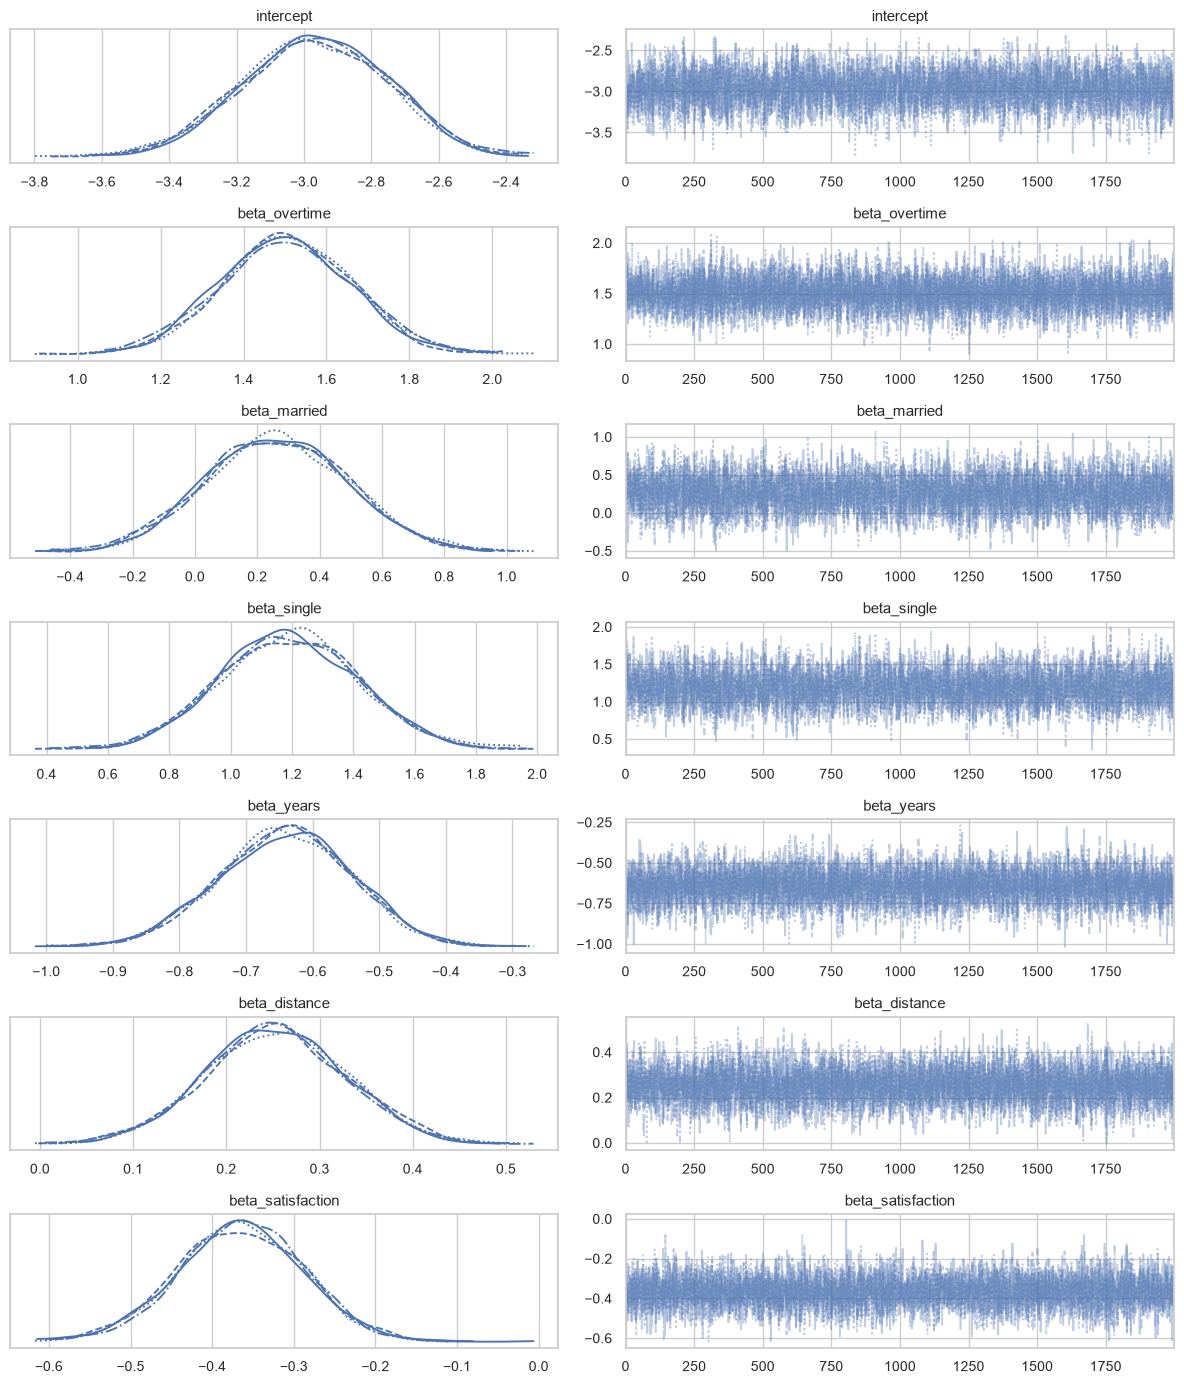

In [9]:
# --- Trace plots: visually confirm the chains are well-mixed ("fuzzy caterpillar" shape) ---
az.plot_trace(
    trace,
    var_names=['intercept', 'beta_overtime', 'beta_married', 'beta_single',
               'beta_years', 'beta_distance', 'beta_satisfaction'],
    compact=True,
)
plt.tight_layout()
plt.show()


## 5. Posterior interpretation

Instead of a single "coefficient = X" number, each driver below has a full posterior
distribution. We report the 94% credible interval — if it excludes zero, we have
strong evidence the effect is real (not just noise); if it straddles zero, the
evidence is weak or ambiguous.


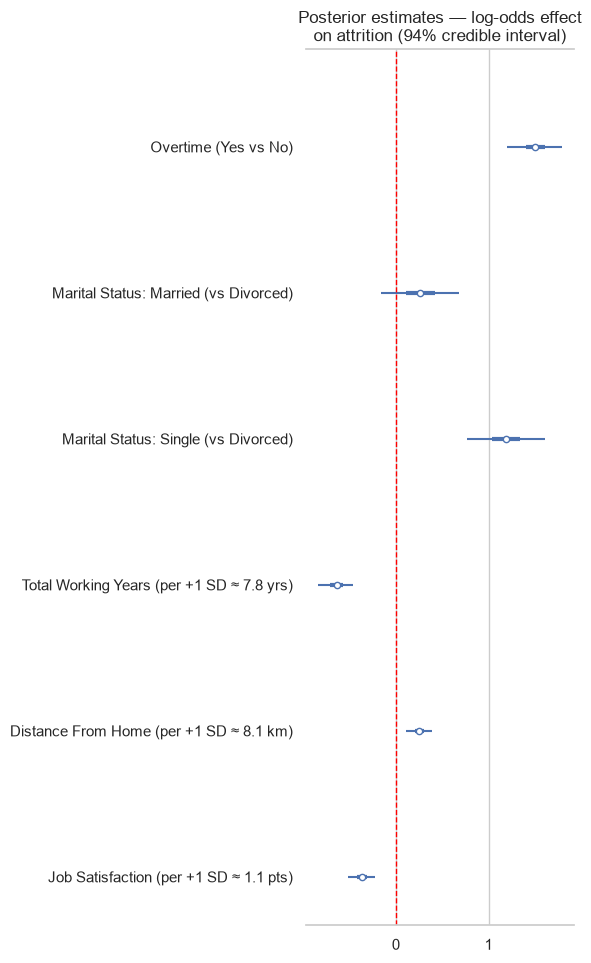

In [10]:
# Relabel raw parameter names to plain-English feature names for the plot
plain_labels = {
    'beta_overtime': 'Overtime (Yes vs No)',
    'beta_married': 'Marital Status: Married (vs Divorced)',
    'beta_single': 'Marital Status: Single (vs Divorced)',
    'beta_years': 'Total Working Years (per +1 SD ≈ 7.8 yrs)',
    'beta_distance': 'Distance From Home (per +1 SD ≈ 8.1 km)',
    'beta_satisfaction': 'Job Satisfaction (per +1 SD ≈ 1.1 pts)',
}

az.plot_forest(
    trace,
    var_names=list(plain_labels.keys()),
    combined=True,
    hdi_prob=0.94,
)
ax = plt.gca()
ax.set_yticklabels(list(plain_labels.values())[::-1])
ax.axvline(0, color='red', linestyle='--', linewidth=1)
plt.title('Posterior estimates — log-odds effect on attrition (94% credible interval)')
plt.tight_layout()
plt.savefig('../outputs/forest_plot.png', dpi=150, bbox_inches='tight')
plt.show()


In [11]:
# --- Convert log-odds coefficients into odds ratios (more interpretable for a business audience) ---
# odds_ratio = exp(coefficient); OR > 1 means the factor increases attrition odds,
# OR < 1 means it decreases them. Interval = 94% equal-tailed credible interval (3rd-97th percentile),
# the same 94% level used for the HDI in the convergence summary above.
coef_names = ['beta_overtime', 'beta_married', 'beta_single', 'beta_years', 'beta_distance', 'beta_satisfaction']

posterior = trace.posterior
odds_ratio_table = []
for name in coef_names:
    samples = posterior[name].values.flatten()
    or_samples = np.exp(samples)
    lo, hi = np.percentile(or_samples, [3, 97])
    odds_ratio_table.append({
        'feature': plain_labels[name],
        'odds_ratio_median': round(np.median(or_samples), 2),
        'odds_ratio_3%': round(lo, 2),
        'odds_ratio_97%': round(hi, 2),
        'credible_effect': 'Yes' if (lo > 1 or hi < 1) else 'Ambiguous',
    })

odds_ratio_df = pd.DataFrame(odds_ratio_table)
odds_ratio_df

,feature,odds_ratio_median,odds_ratio_3%,odds_ratio_97%,credible_effect
0,Overtime (Yes vs No),4.49,3.34,6.07,Yes
1,Marital Status: Married (vs Divorced),1.29,0.85,2.00,Ambiguous
2,Marital Status: Single (vs Divorced),3.29,2.18,5.03,Yes
3,Total Working Years (per +1 SD ≈ 7.8 yrs),0.53,0.44,0.63,Yes
4,Distance From Home (per +1 SD ≈ 8.1 km),1.29,1.12,1.48,Yes
5,Job Satisfaction (per +1 SD ≈ 1.1 pts),0.69,0.60,0.80,Yes


**How to read the odds ratio table:**
- `odds_ratio_median` close to 1 → little to no effect; > 1 → higher attrition odds; < 1 → lower attrition odds, *holding the other predictors constant*.
- Numeric predictors are standardized, so their odds ratio is **per +1 standard deviation**: about 7.8 years of total working experience, 8.1 km of distance, or 1.1 points of job satisfaction.
- `credible_effect = Ambiguous` means the 94% interval includes an odds ratio of 1.

**Results** (exact values in the table above):
- **Overtime** is the strongest driver: about **4.5x the odds** of attrition.
- **Single** employees have about **3.3x the odds** of divorced employees. **Married vs divorced is ambiguous**: the interval includes 1.
- **Total working experience is protective**: each +7.8 years roughly **halves** the odds (OR ≈ 0.53).
- **Distance from home** (OR ≈ 1.3) and **job satisfaction** (OR ≈ 0.7 per +1 SD) are real but smaller effects.

The next cell shows why "4.5x the odds" must not be read as "4.5x the rate".

### Odds ratio ≠ rate ratio

An odds ratio of 4.5 does **not** mean overtime workers leave 4.5 times as often. Odds are p / (1 − p), not p. When the outcome is not rare (16% here), odds ratios come out noticeably larger than rate ratios. The model's odds ratio is also *adjusted* for the other predictors, while the raw rates below are not.

In [12]:
ot_rates = model_df.groupby('OverTime_Yes')['Attrition_binary'].mean()
rate_no, rate_yes = ot_rates[0], ot_rates[1]
odds = lambda p: p / (1 - p)
print(f"Attrition rate - no overtime: {rate_no:.1%} | overtime: {rate_yes:.1%}")
print(f"Rate ratio (raw):             {rate_yes / rate_no:.2f}x")
print(f"Odds ratio (raw, unadjusted): {odds(rate_yes) / odds(rate_no):.2f}x")
print(f"Odds ratio (model, adjusted): {np.median(np.exp(posterior['beta_overtime'].values)):.2f}x")

Attrition rate - no overtime: 10.4% | overtime: 30.5%
Rate ratio (raw):             2.93x
Odds ratio (raw, unadjusted): 3.77x
Odds ratio (model, adjusted): 4.49x


## 6. From-scratch Metropolis-Hastings sampler (validation)

PyMC's NUTS sampler is a highly optimized, gradient-based MCMC method. To check the sampling mechanics independently, we implement a **basic random-walk Metropolis-Hastings sampler by hand**.

For a fair comparison, **both samplers must target the same posterior**. So we fit a simplified single-predictor model, `logit(p) = intercept + beta_overtime * OverTime_Yes`, twice:
1. with the hand-written MH sampler, and
2. with PyMC/NUTS,

and check that the two posteriors agree. The full 6-predictor coefficient is shown alongside only for context: it is a *different* model, so it is expected to differ.

In [13]:
# --- Log-posterior for the simplified single-predictor model ---
# log-posterior = log-likelihood (Bernoulli) + log-prior (Normal(0, 2) on both params)

X_ot = model_df['OverTime_Yes'].values.astype(float)
y_ot = model_df['Attrition_binary'].values.astype(int)

def log_prior(theta):
    intercept, beta = theta
    return (
        -0.5 * (intercept / 2) ** 2
        -0.5 * (beta / 2) ** 2
    )

def log_likelihood(theta, X, y):
    intercept, beta = theta
    logit_p = intercept + beta * X
    # Numerically stable log-likelihood for Bernoulli with a logit link
    log_p = -np.logaddexp(0, -logit_p)       # log(sigmoid(logit_p))
    log_1_minus_p = -np.logaddexp(0, logit_p)  # log(1 - sigmoid(logit_p))
    return np.sum(y * log_p + (1 - y) * log_1_minus_p)

def log_posterior(theta, X, y):
    return log_prior(theta) + log_likelihood(theta, X, y)


In [14]:
# --- Random-walk Metropolis-Hastings sampler ---
def metropolis_hastings(log_post_fn, X, y, n_iter=20000, proposal_sd=0.05, seed=RANDOM_SEED):
    rng_local = np.random.default_rng(seed)
    theta_current = np.array([0.0, 0.0])  # start at (intercept=0, beta=0)
    log_post_current = log_post_fn(theta_current, X, y)

    samples = np.zeros((n_iter, 2))
    n_accepted = 0

    for i in range(n_iter):
        # Propose a new point via a symmetric Gaussian random walk
        theta_proposal = theta_current + rng_local.normal(0, proposal_sd, size=2)
        log_post_proposal = log_post_fn(theta_proposal, X, y)

        # Acceptance ratio in log-space (symmetric proposal -> standard M-H ratio)
        log_accept_ratio = log_post_proposal - log_post_current

        if np.log(rng_local.uniform()) < log_accept_ratio:
            theta_current = theta_proposal
            log_post_current = log_post_proposal
            n_accepted += 1

        samples[i] = theta_current

    acceptance_rate = n_accepted / n_iter
    return samples, acceptance_rate

# Step-size tuning: proposal_sd = 0.05 gave ~73% acceptance, meaning steps far too small, a
# slowly moving chain, and an effective sample size (ESS) of only ~100. proposal_sd = 0.25
# brings acceptance into the ~20-25% range recommended for random-walk Metropolis.
mh_samples, acceptance_rate = metropolis_hastings(log_posterior, X_ot, y_ot, n_iter=40000, proposal_sd=0.25)
print(f"Acceptance rate: {acceptance_rate:.2%}  (target for random-walk Metropolis: roughly 20-40%)")


Acceptance rate: 21.32%  (target for random-walk Metropolis: roughly 20-40%)


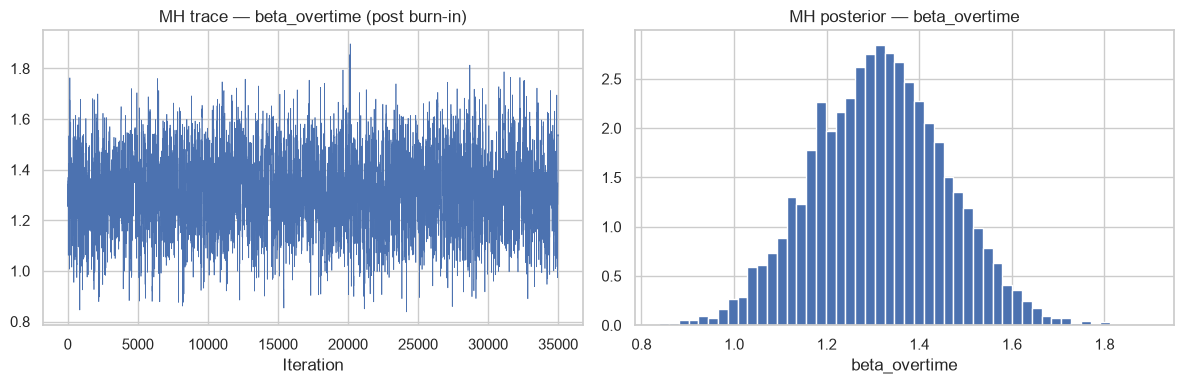

MH posterior mean(beta_overtime): 1.314
MH posterior std(beta_overtime):  0.145
MH effective sample size (beta_overtime): 2439 of 35000 draws


In [15]:
# --- Discard burn-in and inspect the chain ---
burn_in = 5000
mh_intercept = mh_samples[burn_in:, 0]
mh_beta_overtime = mh_samples[burn_in:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(mh_beta_overtime, linewidth=0.5)
axes[0].set_title('MH trace — beta_overtime (post burn-in)')
axes[0].set_xlabel('Iteration')

axes[1].hist(mh_beta_overtime, bins=50, density=True)
axes[1].set_title('MH posterior — beta_overtime')
axes[1].set_xlabel('beta_overtime')
plt.tight_layout()
plt.show()

print(f"MH posterior mean(beta_overtime): {mh_beta_overtime.mean():.3f}")
print(f"MH posterior std(beta_overtime):  {mh_beta_overtime.std():.3f}")
# Effective sample size: how many *independent* draws the autocorrelated chain is worth
print(f"MH effective sample size (beta_overtime): {float(az.ess(mh_beta_overtime)):.0f} of {len(mh_beta_overtime)} draws")


In [16]:
# --- Same single-predictor model, sampled with PyMC/NUTS: the apples-to-apples reference ---
with pm.Model() as overtime_only_model:
    a = pm.Normal('intercept', mu=0, sigma=2)
    b = pm.Normal('beta_overtime', mu=0, sigma=2)
    pm.Bernoulli('y_obs', logit_p=a + b * X_ot, observed=y_ot)
    trace_ot = pm.sample(draws=2000, tune=1000, chains=4, random_seed=RANDOM_SEED, progressbar=False)

nuts_ot_beta = trace_ot.posterior['beta_overtime'].values.flatten()
pymc_beta_overtime = posterior['beta_overtime'].values.flatten()

comparison = pd.DataFrame({
    'sampler / model': ['Hand-written MH (OverTime-only model)',
                        'PyMC NUTS (OverTime-only model): same model, should match',
                        'PyMC NUTS (full 6-predictor model): different model, context only'],
    'posterior_mean': [mh_beta_overtime.mean(), nuts_ot_beta.mean(), pymc_beta_overtime.mean()],
    'posterior_std': [mh_beta_overtime.std(), nuts_ot_beta.std(), pymc_beta_overtime.std()],
}).round(3)
comparison

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [intercept, beta_overtime]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 93 seconds.


,sampler / model,posterior_mean,posterior_std
0,Hand-written MH (OverTime-only model),1.314,0.145
1,"PyMC NUTS (OverTime-only model): same model, s...",1.318,0.146
2,PyMC NUTS (full 6-predictor model): different ...,1.504,0.159


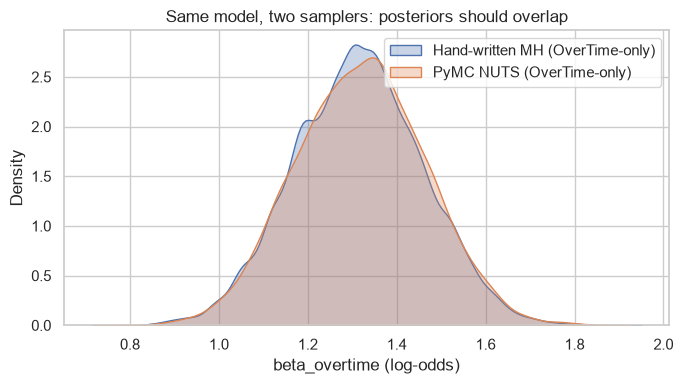

In [17]:
# --- Overlay: hand-written MH vs PyMC NUTS on the SAME model ---
plt.figure(figsize=(7, 4))
sns.kdeplot(mh_beta_overtime, label='Hand-written MH (OverTime-only)', fill=True, alpha=0.3)
sns.kdeplot(nuts_ot_beta, label='PyMC NUTS (OverTime-only)', fill=True, alpha=0.3)
plt.xlabel('beta_overtime (log-odds)')
plt.title('Same model, two samplers: posteriors should overlap')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** the hand-written MH sampler and PyMC/NUTS give matching posteriors for the same single-predictor model (table above). That validates the MH implementation.

The full-model overtime coefficient is larger, because that model adjusts for marital status, experience, distance and satisfaction. This is a modelling difference, not a sampler error.

**Limitation:** an isotropic random walk (the same step size in every direction) mixes slowly here, because the intercept and beta are strongly correlated in the posterior. A proposal shaped by the posterior covariance (x_new = x + s·L·z, with L·Lᵀ = Σ) would mix faster. That is what adaptive Metropolis samplers do.

## 7. Posterior predictive check

A quick check on whether the fitted model can reproduce the basic pattern in the
real data (the overall attrition rate) — not a full model-adequacy audit, but a
useful sanity check.


In [18]:
with attrition_model:
    ppc = pm.sample_posterior_predictive(trace, random_seed=RANDOM_SEED)

ppc_attrition_rate = ppc.posterior_predictive['y_obs'].values.mean()
actual_attrition_rate = y.mean()

print(f"Actual attrition rate in data:      {actual_attrition_rate:.1%}")
print(f"Mean simulated attrition rate (PPC): {ppc_attrition_rate:.1%}")


# A stricter check: does the model reproduce the attrition rate WITHIN each overtime group?
# (Matching the overall rate alone is easy: the intercept does that.)
sim = ppc.posterior_predictive['y_obs'].values.reshape(-1, len(y)).mean(axis=0)
for g, label in [(0, 'No overtime'), (1, 'Overtime')]:
    mask = model_df['OverTime_Yes'].values == g
    print(f"{label:12s} actual {y[mask].mean():.1%} | simulated {sim[mask].mean():.1%}")

Sampling: [y_obs]


Output()

Actual attrition rate in data:      16.1%
Mean simulated attrition rate (PPC): 16.2%
No overtime  actual 10.4% | simulated 10.6%
Overtime     actual 30.5% | simulated 30.5%


## 7b. Where the two strongest drivers overlap

The model says overtime raises risk and experience lowers it. A simple descriptive cut shows how large the combined effect is in practice: attrition rate by overtime × early career (≤ 5 years of total working experience).

In [19]:
seg = model_df.assign(career=np.where(model_df['TotalWorkingYears'] <= 5, 'Early (<=5 yrs)', 'Experienced (>5 yrs)'))
segment_table = (seg.groupby(['OverTime', 'career'])['Attrition_binary']
                    .agg(attrition_rate='mean', employees='size')
                    .reset_index())
segment_table['attrition_rate'] = (segment_table['attrition_rate'] * 100).round(1)
segment_table.to_csv('../outputs/segment_attrition_rates.csv', index=False)
segment_table

,OverTime,career,attrition_rate,employees
0,No,Early (<=5 yrs),18.1,226
1,No,Experienced (>5 yrs),8.3,828
2,Yes,Early (<=5 yrs),55.6,90
3,Yes,Experienced (>5 yrs),23.6,326


## 7c. Formal test: is overtime worse for early-career employees?

Section 7b *observed* that early-career employees on overtime leave at a much higher rate. Here we test that formally with an **interaction model**:

`logit(p) = … + β_ot·OverTime + β_early·Early + β_int·(OverTime × Early) + controls`

- `Early` = 1 if total working experience ≤ 5 years. It replaces the continuous experience variable, so the two don't overlap.
- `β_int` asks whether **overtime's effect on the odds** is different for early-career staff.
- Controls: marital status, distance from home, job satisfaction (same as the main model).

In [20]:
model_df['Early'] = (model_df['TotalWorkingYears'] <= 5).astype(int)
model_df['OT_x_Early'] = model_df['OverTime_Yes'] * model_df['Early']

ot_v = model_df['OverTime_Yes'].values.astype(float)
early_v = model_df['Early'].values.astype(float)
married_v = model_df['Marital_Married'].values.astype(float)
single_v = model_df['Marital_Single'].values.astype(float)
dist_v = model_df['DistanceFromHome_z'].values
sat_v = model_df['JobSatisfaction_z'].values

with pm.Model() as interaction_model:
    a = pm.Normal('intercept', 0, 2)
    b_ot = pm.Normal('beta_overtime', 0, 2)
    b_early = pm.Normal('beta_early', 0, 2)
    b_int = pm.Normal('beta_ot_x_early', 0, 2)
    b_mar = pm.Normal('beta_married', 0, 2)
    b_sin = pm.Normal('beta_single', 0, 2)
    b_dist = pm.Normal('beta_distance', 0, 2)
    b_sat = pm.Normal('beta_satisfaction', 0, 2)

    logit_p = (a + b_ot * ot_v + b_early * early_v + b_int * ot_v * early_v
               + b_mar * married_v + b_sin * single_v + b_dist * dist_v + b_sat * sat_v)
    pm.Bernoulli('y_obs', logit_p=logit_p, observed=y)

    trace_int = pm.sample(draws=2000, tune=1000, chains=4, target_accept=0.9,
                          random_seed=RANDOM_SEED, progressbar=False,
                          idata_kwargs={'log_likelihood': True})

az.summary(trace_int, var_names=['beta_overtime', 'beta_early', 'beta_ot_x_early'], hdi_prob=0.94)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [intercept, beta_overtime, beta_early, beta_ot_x_early, beta_married, beta_single, beta_distance, beta_satisfaction]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 124 seconds.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_overtime,1.344,0.188,1.002,1.711,0.002,0.002,5751.0,5912.0,1.0
beta_early,0.937,0.222,0.530,1.362,0.003,0.002,5703.0,6048.0,1.0
beta_ot_x_early,0.437,0.345,-0.189,1.101,0.005,0.003,5658.0,5618.0,1.0


In [21]:
# --- Interaction on two scales: odds (multiplicative) vs probability (additive) ---
post_i = trace_int.posterior
b_int_s = post_i['beta_ot_x_early'].values.flatten()
or_exp = np.exp(post_i['beta_overtime'].values.flatten())        # overtime OR, experienced staff
or_early = np.exp((post_i['beta_overtime'] + post_i['beta_ot_x_early']).values.flatten())  # early-career staff

def ci(s):
    lo, hi = np.percentile(s, [3, 97])
    return f"{np.median(s):.2f} (94% CrI {lo:.2f}-{hi:.2f})"

print("Odds scale")
print("  Overtime odds ratio, experienced staff:  ", ci(or_exp))
print("  Overtime odds ratio, early-career staff: ", ci(or_early))
print(f"  P(beta_ot_x_early > 0) = {(b_int_s > 0).mean():.2f}")

# Probability scale: extra attrition probability from overtime for each actual employee,
# computed from the posterior draws with overtime switched on vs off.
# Use the posterior mean probability per draw (not 0/1 simulated outcomes) for smoother estimates
def prob_matrix(ot_value):
    lp = (post_i['intercept'].values[..., None] + post_i['beta_overtime'].values[..., None] * ot_value
          + post_i['beta_early'].values[..., None] * early_v
          + post_i['beta_ot_x_early'].values[..., None] * ot_value * early_v
          + post_i['beta_married'].values[..., None] * married_v
          + post_i['beta_single'].values[..., None] * single_v
          + post_i['beta_distance'].values[..., None] * dist_v
          + post_i['beta_satisfaction'].values[..., None] * sat_v)
    return (1 / (1 + np.exp(-lp))).reshape(-1, len(y))   # (draws, employees)

P_on, P_off = prob_matrix(1.0), prob_matrix(0.0)
uplift = P_on - P_off                                      # extra attrition probability from overtime
ud_early = uplift[:, early_v == 1].mean(axis=1)
ud_exp = uplift[:, early_v == 0].mean(axis=1)
print("\nProbability scale (percentage points of attrition added by overtime)")
print("  Early-career staff: ", ci(ud_early * 100))
print("  Experienced staff:  ", ci(ud_exp * 100))
print(f"  P(overtime adds more attrition for early-career staff) = {(ud_early > ud_exp).mean():.2f}")

Odds scale
  Overtime odds ratio, experienced staff:   3.83 (94% CrI 2.70-5.49)
  Overtime odds ratio, early-career staff:  5.92 (94% CrI 3.48-10.20)
  P(beta_ot_x_early > 0) = 0.89



Probability scale (percentage points of attrition added by overtime)
  Early-career staff:  35.17 (94% CrI 24.56-45.63)
  Experienced staff:   15.85 (94% CrI 11.41-20.65)
  P(overtime adds more attrition for early-career staff) = 1.00


**How to read this:** an interaction can look small on one scale and large on another.

- **Odds scale:** overtime multiplies the odds of leaving by about **5.9x for early-career staff vs 3.8x for experienced staff**. There is an 89% posterior probability that the effect really is larger for early-career staff, but the interaction's 94% interval still includes 0. With only 90 employees who are both early-career and on overtime, the data can't pin it down.
- **Probability scale:** overtime adds about **35 percentage points** of attrition for early-career staff vs **16** for experienced staff. That difference is clear (posterior probability ≈ 1.00), because early-career staff start from a higher baseline risk, so the same multiplier adds far more departures.

**Conclusion:** the 56% attrition rate in this segment is mostly **two risk factors stacking**, possibly with some extra overtime effect for new employees that this sample is too small to confirm. For a business decision, the probability scale is what matters: that is where the departures are.

## 7d. Impact estimate: what if the highest-risk group stopped working overtime?

A **what-if** using the interaction model: for the 90 early-career employees currently on overtime, compare predicted departures with overtime on vs off.

⚠️ This treats the model's association as if it were causal. It is an *upper-bound planning estimate* for sizing a pilot, not a guaranteed result.

In [22]:
target = (early_v == 1) & (ot_v == 1)
dep_now = P_on[:, target].sum(axis=1)          # expected departures, overtime as-is
dep_off = P_off[:, target].sum(axis=1)         # expected departures, overtime removed
avoided = dep_now - dep_off

all_ot = ot_v == 1
avoided_all = (P_on[:, all_ot] - P_off[:, all_ot]).sum(axis=1)

print(f"Early-career employees on overtime: {target.sum()} (actually left: {y[target].sum()})")
print(f"  Expected departures with overtime:    {np.median(dep_now):.0f}")
print(f"  Expected departures without overtime: {np.median(dep_off):.0f}")
print(f"  Departures avoided: {ci(avoided)}")
print(f"\nFor comparison, ALL {all_ot.sum()} overtime employees: departures avoided {ci(avoided_all)}")
print(f"Share of the total impact from the early-career group: {np.median(avoided / avoided_all):.0%} "
      f"of the impact from {target.sum() / all_ot.sum():.0%} of the overtime workforce")

impact = pd.DataFrame({
    'group': ['Early-career on overtime', 'All overtime employees'],
    'employees': [int(target.sum()), int(all_ot.sum())],
    'departures_avoided_median': [np.median(avoided), np.median(avoided_all)],
    'ci_3%': [np.percentile(avoided, 3), np.percentile(avoided_all, 3)],
    'ci_97%': [np.percentile(avoided, 97), np.percentile(avoided_all, 97)],
}).round(1)
impact.to_csv('../outputs/impact_estimate.csv', index=False)
impact

Early-career employees on overtime: 90 (actually left: 50)
  Expected departures with overtime:    50
  Expected departures without overtime: 18
  Departures avoided: 31.85 (94% CrI 22.36-41.15)

For comparison, ALL 416 overtime employees: departures avoided 82.40 (94% CrI 65.37-100.46)
Share of the total impact from the early-career group: 39% of the impact from 22% of the overtime workforce


,group,employees,departures_avoided_median,ci_3%,ci_97%
0,Early-career on overtime,90,31.8,22.4,41.1
1,All overtime employees,416,82.4,65.4,100.5


**Result:** of the 90 early-career employees on overtime, 50 actually left. The model expects about **18** departures without overtime, so about **32 departures avoided** (94% CrI ≈ 22–41).

This group is only **22% of overtime workers but about 39% of the avoidable departures**, which makes it the obvious place to start a pilot. (Planning estimate only: it assumes the association is causal.)

In [23]:
# --- Does the interaction model fit better than the main model? (LOO cross-validation) ---
with attrition_model:
    pm.compute_log_likelihood(trace, progressbar=False)
az.compare({'main (continuous experience)': trace, 'interaction (overtime x early)': trace_int}, ic='loo')

,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
main (continuous experience),0,-551.165880,7.346822,0.000000,0.637907,24.772445,0.000000,False,log
interaction (overtime x early),1,-555.106146,7.939560,3.940266,0.362093,24.017667,6.846707,False,log


**Model comparison:** `elpd_loo` estimates out-of-sample predictive accuracy (higher is better), and `dse` is the standard error of the difference.

The main model scores slightly higher (difference ≈ 3.9), but that is well within 2 × `dse` (≈ 13.7), so **the two models predict about equally well**. The interaction model's value is **interpretability**: it answers the segment question directly. It does not predict better.

## 7e. How this transfers to product analytics (e.g. Paytm)

The same workflow applies directly to **user churn** in a payments app:

| This project | Payments-app equivalent |
|---|---|
| Employee leaves | User stops transacting for 30+ days |
| Overtime, experience, distance | Failed transactions, days since sign-up, cashback received, app version |
| Early-career × overtime segment | New users who hit a payment failure in week 1 |
| "Departures avoided" what-if | "Churned users avoided if first-week failures were halved", to size a fix before building it |
| Overtime pilot | A/B test: e.g. instant auto-retry on failed payments for new users |

## 8. Save outputs for the executive summary

Persist the odds-ratio table so it can be pulled directly into a plain-language
write-up (e.g. `04_executive_summary`) without re-running the model.


In [24]:
odds_ratio_df.to_csv('../outputs/bayesian_model_odds_ratios.csv', index=False)
summary.to_csv('../outputs/bayesian_model_convergence_summary.csv')
print("Saved: ../outputs/bayesian_model_odds_ratios.csv")
print("Saved: ../outputs/bayesian_model_convergence_summary.csv")


Saved: ../outputs/bayesian_model_odds_ratios.csv
Saved: ../outputs/bayesian_model_convergence_summary.csv


## Conclusion

- **Overtime is the strongest and most credible driver of attrition**: about 4.5x the odds after adjusting for the other factors. In raw terms, 30.5% of overtime workers left vs 10.4% of others, a 2.9x rate ratio.
- **Experience is strongly protective** (the odds roughly halve per +7.8 years), and **single employees** are at higher risk than divorced ones. Married vs divorced was **ambiguous**, even though marital status as a whole was "significant" in the chi-square test.
- **Early-career employees on overtime** are the highest-risk segment: over half of them left (see 7b).
- **Caveats:** this is association, not causation. The data is a single cross-sectional snapshot of a synthetic IBM dataset, and the model has 6 predictors for 237 attrition events.

The plain-language version is in `outputs/executive_summary.md` / `.pdf`.